# 05 · Label-free landscape typology (Fig. 3)
**Question.** Does the landscape, summarised *without* drying labels or survey fields, structure
recorded drying?

**Method.** 46 continuous GIS covariates -> standardisation -> PCA (90 % of variance) -> Gaussian
mixtures (K = 2-12) selected by BIC subject to bootstrap stability (mean ARI >= 0.75; the rule was fixed
before drying was examined). The same module builds the contiguous landscape regions, the ward funnel
plot and the ward ICC of recalled attributes (`src/unsupervised.py`).

Running this notebook reproduces every `un_*` table and `data/processed/landscape_types.csv`
(a few minutes).

In [1]:
import logging, os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", stream=sys.stdout, force=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

M = ROOT / "results/metrics"
F = ROOT / "results/figures"

def table(name, **kw):
    return pd.read_csv(M / name, **kw).round(4)

def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.unsupervised import run as run_unsupervised
run_unsupervised()

2026-11-10 15:54:05,901 [INFO] U1 landscape typology


  File "C:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


2026-11-10 15:57:36,482 [INFO] 
     K         bic  stability_ari_mean  stability_ari_sd  min_type_share  selected
0    2  306498.134               0.946             0.026           0.146     False
1    3  297834.836               0.945             0.028           0.043     False
2    4  284895.336               0.892             0.073           0.041     False
3    5  278939.236               0.466             0.217           0.036     False
4    6  275112.572               0.556             0.179           0.046     False
5    7  270704.601               0.735             0.183           0.040     False
6    8  267640.966               0.839             0.115           0.036      True
7    9  265670.748               0.660             0.078           0.039     False
8   10  263686.971               0.649             0.095           0.006     False
9   11  263192.756               0.566             0.071           0.022     False
10  12  260906.968               0.620             0.06

2026-11-10 15:57:36,483 [INFO] U2 regionalisation


2026-11-10 15:57:39,944 [INFO] 
                  partition  n_units  mean_sources_per_unit  env_r2  icc_drying  grid_cell_km  grid_icc_mean  grid_icc_q025  grid_icc_q975  p_above_grid  ari_with_ward  nmi_with_ward  grid_env_r2_mean  grid_ari_with_ward_mean
0        ward (survey unit)       75                 75.853   0.522       0.132         3.563          0.099          0.093          0.106         0.005          1.000          1.000             0.504                    0.415
1     DEM catchment T=2 km²      176                 32.324   0.567       0.122         2.166          0.126          0.115          0.135         0.801          0.434          0.796             0.595                    0.430
2              municipality        7                812.714   0.294       0.067        19.347          0.043          0.029          0.056         0.005          0.153          0.616             0.215                    0.056
3   landscape region (n=75)       75                 75.853   0.

2026-11-10 15:57:39,945 [INFO] U3 dried-source mining


2026-11-10 15:57:40,978 [INFO] 
                     outcome  share            unit  n_units    icc  grid_icc_mean  grid_icc_q025  grid_icc_q975  p_above_grid  cramers_v
0      earthquake attributed  0.343            ward       75  0.228          0.152          0.131          0.177         0.005      0.462
1      earthquake attributed  0.343  landscape type        8  0.050            NaN            NaN            NaN           NaN      0.200
2         drought attributed  0.314            ward       75  0.251          0.187          0.155          0.224         0.005      0.485
3         drought attributed  0.314  landscape type        8  0.039            NaN            NaN            NaN           NaN      0.176
4  infrastructure attributed  0.158            ward       75  0.264          0.180          0.152          0.208         0.005      0.498
5  infrastructure attributed  0.158  landscape type        8  0.144            NaN            NaN            NaN           NaN      0.343
6 

2026-11-10 15:57:40,979 [INFO] U4 ward funnel against a landscape-only model


2026-11-10 15:57:41,015 [INFO] 
   n_wards  overdispersion_phi  chi2_p  n_outside_95  expected_outside_95  n_outside_998  expected_outside_998  n_high_998  n_low_998
0       75               5.488     0.0            26                 3.75             13                  0.15           6          7


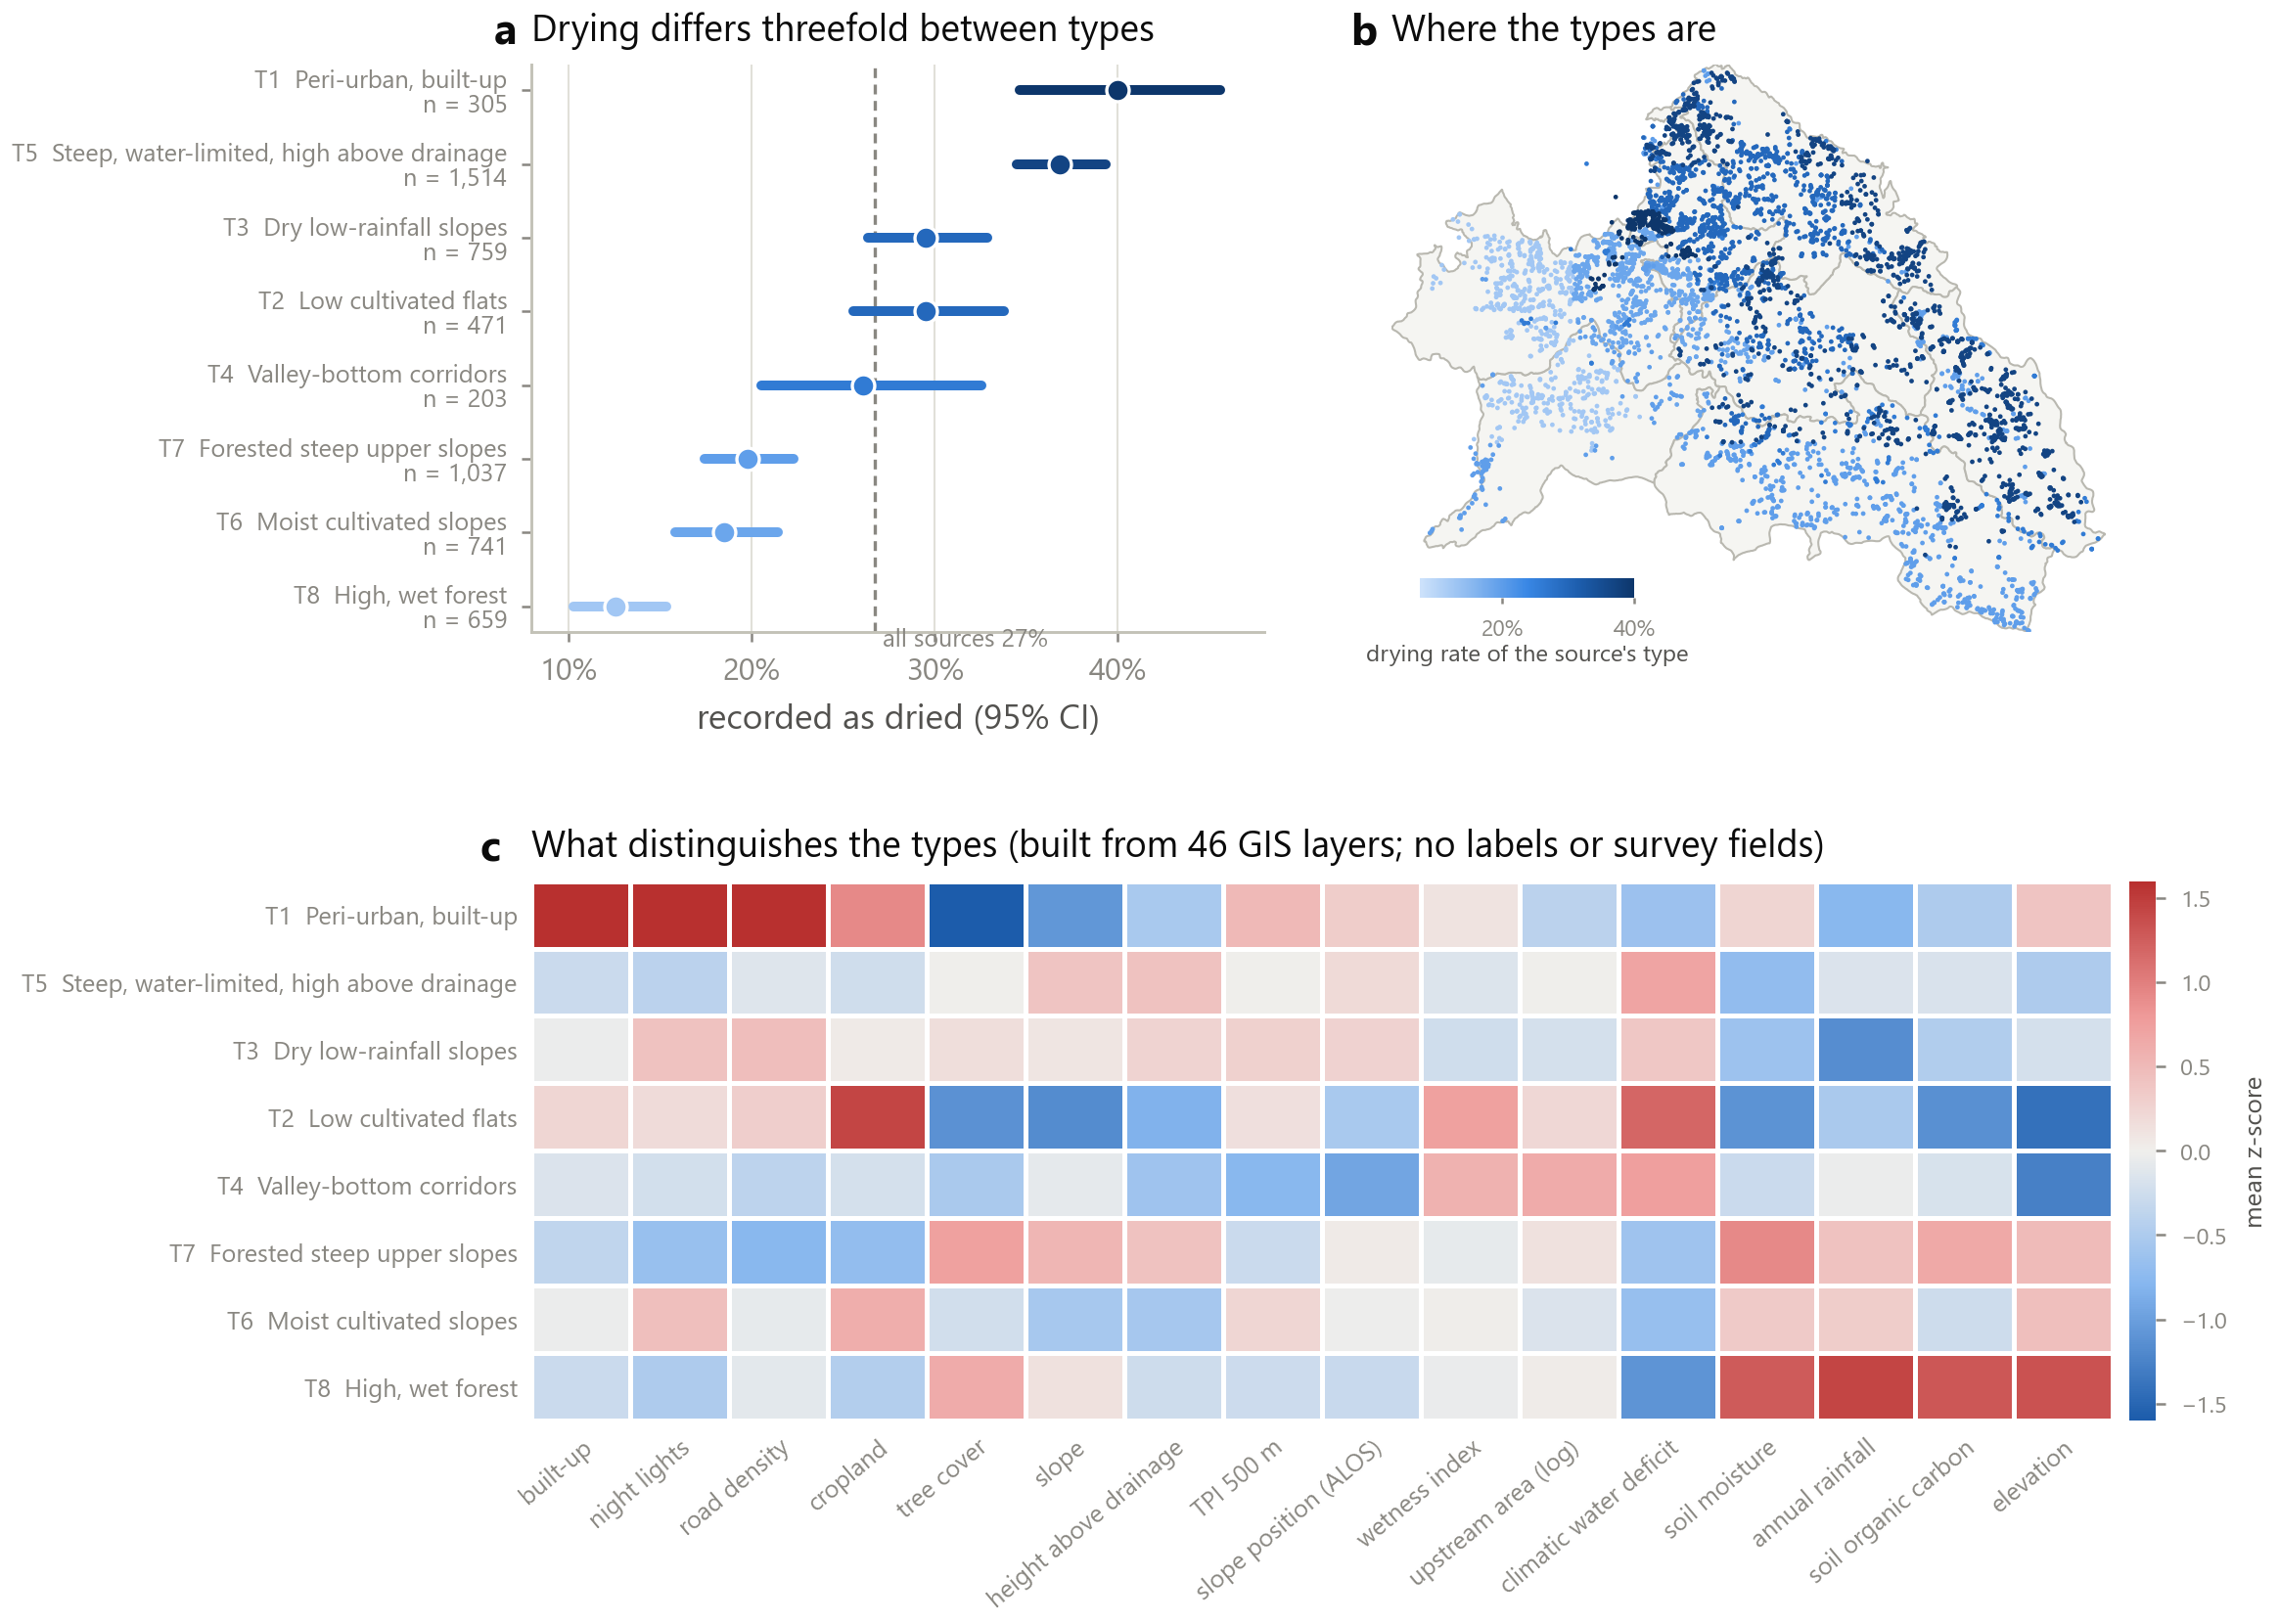

In [3]:
fig("fig3_landscape_types.png")

## PCA, model selection and the eight types

In [4]:
display(table("un_pca_variance.csv").T)
display(table("un_typology_selection.csv"))
table("un_typology_drying.csv")

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
pc,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19
explained_variance_ratio,0.2346,0.1475,0.0966,0.0574,0.0502,0.0389,0.0348,0.0326,0.0296,0.0252,0.0244,0.0221,0.0197,0.0185,0.0162,0.0153,0.0145,0.0135,0.0123


,K,bic,stability_ari_mean,stability_ari_sd,min_type_share,selected
0,2,306498.1339,0.9464,0.0259,0.1455,False
1,3,297834.8359,0.9446,0.0280,0.0432,False
2,4,284895.3361,0.8920,0.0729,0.0408,False
3,5,278939.2358,0.4664,0.2171,0.0355,False
4,6,275112.5717,0.5562,0.1788,0.0464,False
5,7,270704.6010,0.7347,0.1827,0.0396,False
6,8,267640.9655,0.8393,0.1147,0.0357,True
7,9,265670.7478,0.6597,0.0779,0.0388,False
8,10,263686.9710,0.6487,0.0947,0.0060,False
9,11,263192.7561,0.5661,0.0708,0.0218,False


,type,n_sources,share_ponds,n_wards_present,drying_rate,ci_low,ci_high
0,T1,305,0.1902,14,0.4000,0.3466,0.4559
1,T2,471,0.2845,23,0.2951,0.2557,0.3378
2,T3,759,0.1028,33,0.2951,0.2638,0.3285
3,T4,203,0.0493,38,0.2611,0.2055,0.3255
4,T5,1514,0.0911,48,0.3686,0.3446,0.3932
5,T6,741,0.0364,24,0.1849,0.1586,0.2144
6,T7,1037,0.0608,55,0.1977,0.1746,0.2230
7,T8,659,0.0197,12,0.1259,0.1028,0.1535


## Type against ward

In [5]:
display(table("un_typology_vs_ward_lrt.csv"))
table("un_typology_summary.csv")

,test,lr_stat,df,p,adj_pseudo_r2_model
0,type (vs null),237.5356,7,0.0,0.0338
1,ward (vs null),846.0502,74,0.0,0.1057
2,type | ward,55.9202,7,0.0,0.1120
3,ward | type,664.4348,74,0.0,0.1120


,chi2,df,p,cramers_v_type_drying,cramers_v_ward_drying,cramers_v_type_ward
0,230.1446,7,0.0,0.1981,0.3583,0.7416


## Explore: drying rate by type within each municipality

In [6]:
from src.dataset import load_master
df = load_master().merge(pd.read_csv(ROOT / "data/processed/landscape_types.csv"), on="id")
pd.crosstab(df.municipality, df.env_type, values=df.target_dried, aggfunc="mean").round(3)

env_type,T1,T2,T3,T4,T5,T6,T7,T8
municipality,,,,,,,,
Bethanchownk,NaN,NaN,NaN,0.000,NaN,0.429,0.144,0.194
Dhulikhel,0.421,0.250,0.263,0.391,0.109,0.300,0.235,NaN
Namobuudha,NaN,0.122,0.206,0.273,0.203,0.269,0.111,NaN
Panauti,0.235,NaN,NaN,0.118,NaN,0.091,0.150,0.082
Panchkhal,NaN,0.331,0.438,0.143,0.436,NaN,0.536,NaN
Roshi RM,NaN,0.143,0.500,0.172,0.429,0.000,0.174,NaN
Temal,NaN,NaN,NaN,0.342,0.420,NaN,0.336,NaN
